<a href="https://colab.research.google.com/github/alimoorreza/CS181-fall26-notes/blob/main/day22_generative_model_diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##__Make sure you are connected to GPU__
####__you won't be able to generate any image with cpu version of Stable Diffusion__

In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
import torch
import torchvision
print(f"torch.__version__: {torch.__version__}")
print(f"torchvision.__version__: {torchvision.__version__}")

root = '/content/drive/MyDrive/cs181_fall26/module_7_generative_model/module_7_generative_model_diffusion/'

torch.__version__: 2.4.1+cu121
torchvision.__version__: 0.19.1+cu121


##__Stable Diffusion__
- [https://github.com/CompVis/stable-diffusion](https://github.com/CompVis/stable-diffusion?tab=readme-ov-file)

In [2]:
import torch
from diffusers import StableDiffusionPipeline
from matplotlib import pyplot
from PIL import Image
pipe = StableDiffusionPipeline.from_pretrained("runwayml/stable-diffusion-v1-5", torch_dtype=torch.float16)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

#__Generate image from text prompt__
- [https://stable-diffusion-art.com/prompt-guide](https://stable-diffusion-art.com/prompt-guide/)

  0%|          | 0/50 [00:00<?, ?it/s]

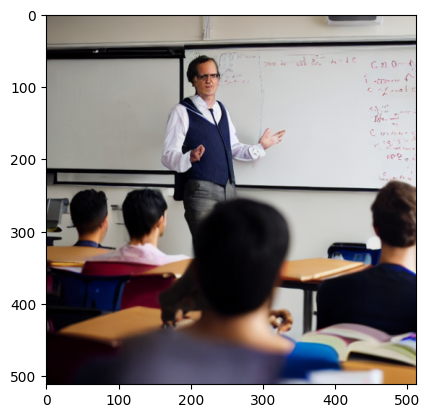

In [3]:
prompt  = "a photo of a professor teaching in a class"
pipe    = pipe.to("cuda")
image   = pipe(prompt).images[0]

image.save(root + 'professor_in_class.png') # save the image
pyplot.imshow(image)

#__Generate another image from a text prompt__

  0%|          | 0/50 [00:00<?, ?it/s]

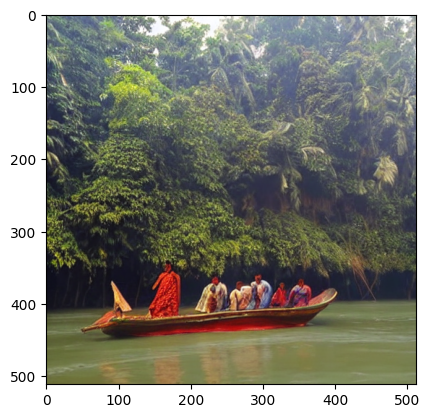

In [4]:
prompt  = "a photo of a boat ride on a river in Bangladesh"
pipe    = pipe.to("cuda")
image   = pipe(prompt).images[0]

image.save(root + 'boat_on_river.png') # save the image
pyplot.imshow(image)

#__Generate a fantasy image from text prompt__

  0%|          | 0/50 [00:00<?, ?it/s]

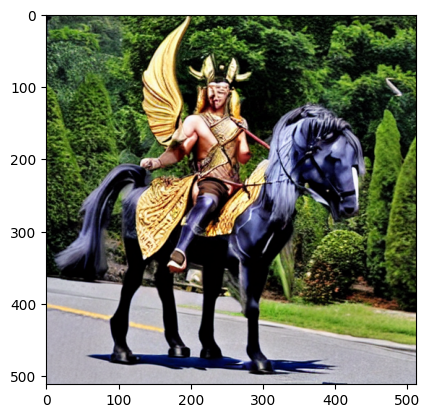

In [5]:
prompt  = 'A charming mythical hero, mounted on a chariot.'
pipe    = pipe.to("cuda")
image   = pipe(prompt).images[0]

image.save( root + 'charming_mythical_hero.png') # save the image
pyplot.imshow(image)



  0%|          | 0/50 [00:00<?, ?it/s]

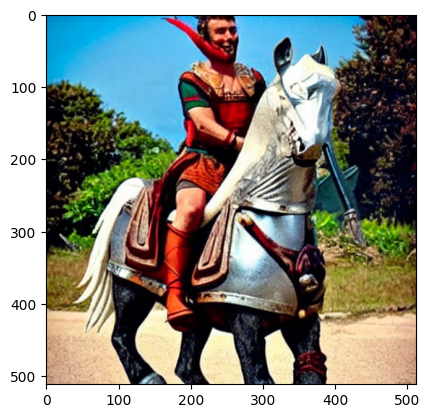

In [6]:
prompt  = 'A charming mythical hero, mounted on a chariot.'
pipe    = pipe.to("cuda")
image   = pipe(prompt).images[0]

image.save(root + '/charming_mythical_hero_SD.png') # save the image
pyplot.imshow(image)



#__Group activity#1: Generate images following the Stable Diffusion guide__
- [https://stable-diffusion-art.com/prompt-guide](https://stable-diffusion-art.com/prompt-guide/)

In [ ]:
# your code
# ...
# ...
# ...


##__Denoising Diffusion Probabilistic Models (DDPM)__

* [DDPM model on huggingface](https://huggingface.co/google/ddpm-cat-256)

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

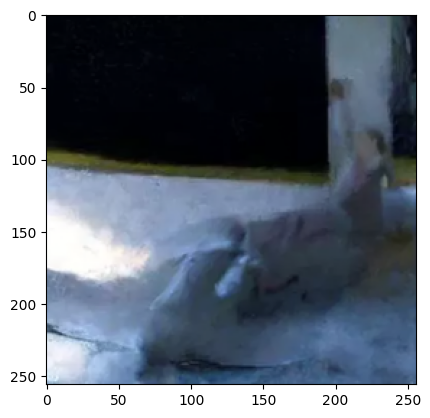

In [8]:
from diffusers import DDPMPipeline

pipe    = DDPMPipeline.from_pretrained("google/ddpm-cat-256")
pipe    = pipe.to("cuda")
image   = pipe().images[0] # run pipeline in inference (sample random noise and denoise; NO PROMPT)
image.save(root + 'randomly_generate_image_DDPM1.png') # save the image
pyplot.imshow(image)


  0%|          | 0/1000 [00:00<?, ?it/s]

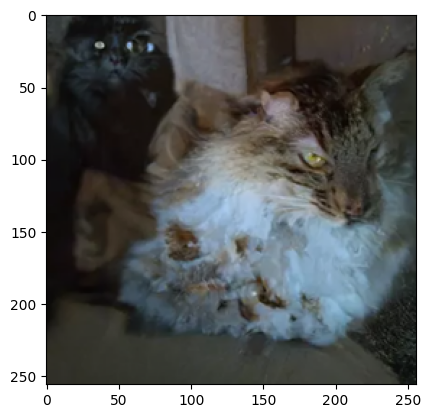

In [9]:
image   = pipe().images[0] # run pipeline in inference (sample random noise and denoise; NO PROMPT)
image.save(root + 'randomly_generate_image_DDPM2.png') # save the image
pyplot.imshow(image)
